# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 10 баллов за основную часть

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. **Дополнительно, по желанию:** выгрузить витрину в BigQuery и повторить расчёт (необязательный раздел; основная работа полностью выполняется в SQLite).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

## Алгоритм выполнения работы

Вся работа строится как один конвейер: сырые файлы проходят контроль, чистятся, ложатся
в реляционную базу и только потом превращаются в цифры и графики. Схема конвейера:

**Источники (CSV/XLSX/JSON) → аудит качества (6 измерений) → очистка и карантин → SQLite (PK/FK/CHECK) → SQL и pandas (свёртка цен до события) → витрина и графики → выводы и рекомендации**

Пошаговый алгоритм:

1. **Окружение и вариант.** Выбираю номер варианта (12); от него детерминированно
   зависят предметная область, состав источников, объёмы и seed генератора.
   Вход — номер варианта, выход — конфигурация `CFG` и рабочая папка.
2. **Генерация источников.** Код создаёт три файла разных форматов: справочник
   агентств (CSV), события-договоры с объёмом (XLSX), тарифные ставки (JSON).
   В данные намеренно встроены дефекты — их и предстоит поймать.
3. **Загрузка «как есть».** Все три файла читаю строками, без «умного» приведения
   типов: сырой вид данных важнее удобства, ведущие нули и форматы должны дожить
   до аудита нетронутыми.
4. **Профиль источников.** По каждой колонке собираю тип, долю заполненных ячеек,
   число уникальных значений и пару примеров — это карта данных перед проверками.
5. **Аудит по шести измерениям.** Полнота, уникальность, согласованность, валидность,
   целостность, точность. Каждая найденная проблема попадает в журнал `issues` с числом
   строк и решением; пустые результаты тоже фиксирую честно.
6. **Кардинальность связей.** Считаю, сколько событий приходится на агентство и сколько
   тарифных строк — на событие. Здесь главная развилка работы: если у события несколько
   ставок, прямое соединение таблиц размножит его объём (fan-out) и завысит выручку.
   Поэтому ставки сворачиваются до одной строки **до** соединения с объёмом.
7. **Очистка с журналом.** Снимаю дубликаты по ключам, разбираю оба формата дат и числа
   с валютой, имена привожу к единому виду. Строки с битыми ссылками и непригодными
   значениями уходят в карантин, а не в корзину; каждая операция пишется в `CLEAN_LOG`.
   Пропуски остаются пропусками — нулями их не подменяю.
8. **SQLite и расчёт выручки.** Создаю схему с первичными и внешними ключами,
   ограничениями CHECK и индексами, загружаю очищенные данные. Двумя запросами
   показываю ловушку fan-out: «в лоб» против CTE со свёрткой; разницу фиксирую
   коэффициентом завышения. Тот же расчёт повторяю в pandas и сверяю — расхождение
   должно быть на уровне округления.
9. **Витрина и аналитика.** Построчные события с выручкой выгружаю в CSV и в таблицы
   `dm_revenue_events` / `dm_revenue_agents` базы; по четырём графикам (выручка по
   агентствам, Парето с группами ABC, сезонность, структура по видам страхования)
   смотрю концентрацию, сезонность и структуру. Сумма любого разреза обязана сойтись
   с итоговой выручкой.
10. **Выводы и рекомендации.** Концентрация, сезонный разрыв, средняя премия по видам
    страхования и вклад агентств; три рекомендации с ожидаемым эффектом и способом
    проверки; ограничения данных.

Перед сдачей ноутбук прогоняется сверху вниз, и ячейка самопроверки должна показать
**11 из 11** выполненных требований — пока хоть один пункт красный, работу правлю и
прогоняю заново.


### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [1]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 12                 #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = False      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.11.12 | pandas 2.2.2 | numpy 1.26.4 | sqlite3 3.54.1
Рабочая папка: pw2_work


In [2]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 12 — Страхование
Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит
качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»

CSV  : Агентства        (справочник субъектов)
XLSX : Договоры          (события, объём в единицах: объектов)
JSON : Тарифные ставки          (цены, разрез: вид страхования)

Объём генерации: субъектов 10, событий 3 000, уровень дефектов ★
Аналитическая задача: Средняя премия по видам страхования и вклад агентств


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

In [3]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,                      # регион совпадает с городом в названии
        "founded_year": rng.integers(1990, 2021, n),
    })
    # дефекты справочника: дубль строки, «грязное» имя, пропуск в регионе
    parents.loc[len(parents)] = parents.iloc[1].tolist()                       # полный дубликат
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)
    # сезонность: летние и декабрьские месяцы нагружены сильнее
    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        "route": [f"{a} — {b}" for a, b in zip(rng.choice(regions, m), rng.choice(regions, m))],
        "volume_units": volume,
        "asset_type": rng.choice(["Тип A", "Тип B", "Тип C", "Тип D"], m),
    })
    # дефекты событий
    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [                                   # другой формат даты
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None                              # пропуски объёма
    events.loc[part_text, "volume_units"] = [                                 # число строкой с пробелом
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:                                                               # строки-сироты по FK
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:                                                               # дубли событий
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = [f"{cfg['cls']} 1", f"{cfg['cls']} 2", f"{cfg['cls']} 3"]
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):        # 1–3 строки цен на событие → fan-out
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)
    # дефекты цен
    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [                                      # цена строкой с валютой
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None                                   # пропуски
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:                                                                 # дубли строк цен
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:       11   размер:      0.7 КБ
events.xlsx     строк:    3 000   размер:    104.2 КБ
prices.json     строк:    6 023   размер:    802.9 КБ

Файлы лежат в: pw2_work/data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [4]:
#@title Шаг 3. Загрузка источников и аудит качества (задание) { display-mode: "form" }
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}

# ------------------------------------------------------------------ TODO 3.1
def profile_table(df, name):
    """Профиль таблицы: по каждой колонке тип, доля заполненных ячеек, уникальных
    значений и пара примеров. Всё читаю как строки — типы в данных проверяю сам."""
    stat = []
    for col in df.columns:
        s = df[col]
        filled = s.notna() & (s.astype(str).str.strip() != "")
        stat.append({
            "источник": name,
            "колонка": col,
            "тип": str(s.dtype),
            "заполнено, %": round(100 * float(filled.mean()), 1),
            "уникальных": int(s.nunique(dropna=True)),
            "примеры": " | ".join(s[filled].astype(str).head(2)),
        })
    return pd.DataFrame(stat)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()],
                     ignore_index=True)
print("Профиль трёх источников")
display(profiles)

# ------------------------------------------------------------------ TODO 3.2
issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})

def as_number(series):
    """Черновой перевод колонки в число: срезаю валюту и пробелы, запятую считаю
    десятичным разделителем (если рядом есть точка, запятая разрядная)."""
    txt = (series.astype(str)
           .str.replace(r"[^\d,.\-]", "", regex=True)
           .str.replace(" ", "", regex=False))
    both = txt.str.contains(",", na=False) & txt.str.contains(r"\.", na=False)
    txt = txt.mask(both, txt.str.replace(",", "", regex=False))
    txt = txt.mask(~both, txt.str.replace(",", ".", regex=False))
    return pd.to_numeric(txt, errors="coerce")

NAME_CSV = "CSV · " + CFG["parent"]
NAME_XLSX = "XLSX · " + CFG["event"]
NAME_JSON = "JSON · " + CFG["price"]

# --- 1. Полнота: пустые ячейки по каждой колонке
for name, df in SOURCES.items():
    for col in df.columns:
        empty = int(df[col].isna().sum() + (df[col].astype(str).str.strip() == "").sum())
        if empty:
            add_issue("Полнота", name, f"пустые ячейки в «{col}»", empty,
                      "пропуск остаётся NaN, строка выпадает из расчёта выручки")

# --- 2. Уникальность: полные дубликаты и повторы ключей
add_issue("Уникальность", NAME_CSV, "полный дубликат строки справочника",
          int(raw_entities.duplicated().sum()), "снять копии, оставить первый экземпляр")
add_issue("Уникальность", NAME_XLSX, "повторяющийся event_id",
          int(raw_events["event_id"].duplicated().sum()),
          "проверено, повторов нет" if raw_events["event_id"].duplicated().sum() == 0
          else "оставить первую запись ключа")
add_issue("Уникальность", NAME_JSON, "повторяющийся price_id",
          int(raw_prices["price_id"].duplicated().sum()), "оставить первую запись ключа")

# --- 3. Согласованность: смешанные форматы записи дат и чисел
add_issue("Согласованность", NAME_XLSX, "дата в формате дд.мм.гггг вместо ISO",
          int(raw_events["event_date"].astype(str).str.match(r"\d{2}\.\d{2}\.\d{4}").sum()),
          "разобрать оба формата в один тип datetime")
add_issue("Согласованность", NAME_JSON, "ставка записана текстом с валютой «₽»",
          int(raw_prices["unit_price"].astype(str).str.contains("₽").sum()),
          "вырезать валюту и пробелы, привести к числу")
add_issue("Согласованность", NAME_XLSX, "объём строкой с хвостовым пробелом",
          int(raw_events["volume_units"].astype(str).str.match(r"^\d+\s+$").sum()),
          "обрезать пробелы, привести к числу")

# --- 4. Валидность: невозможные значения (замеряем честно, даже если ноль)
neg = int((as_number(raw_prices["unit_price"]) < 0).sum())
add_issue("Валидность", NAME_JSON, "отрицательная тарифная ставка", neg,
          "проверено: таких строк нет" if neg == 0 else "исключить из расчёта")
bad_vol = int((as_number(raw_events["volume_units"]) <= 0).sum())
add_issue("Валидность", NAME_XLSX, "объём нулевой или отрицательный", bad_vol,
          "проверено: таких строк нет" if bad_vol == 0 else "исключить из расчёта")

# --- 5. Целостность: ссылки на отсутствующие записи
known_ids = set(raw_entities["entity_id"])
broken_fk = int((~raw_events["entity_id"].isin(known_ids)).sum())
add_issue("Целостность", NAME_XLSX, "ссылка на агентство вне справочника", broken_fk,
          "проверено: на этом уровне дефектов сирот нет" if broken_fk == 0
          else "вынести в карантин quarantine_fk")
lost_prices = int((~raw_prices["event_id"].isin(set(raw_events["event_id"]))).sum())
add_issue("Целостность", NAME_JSON, "ставка без события", lost_prices,
          "проверено: таких строк нет" if lost_prices == 0 else "вынести в карантин")

# --- 6. Точность: выбросы по правилу трёх межквартильных размахов
p = as_number(raw_prices["unit_price"]).dropna()
q1, q3 = float(p.quantile(0.25)), float(p.quantile(0.75))
iqr = q3 - q1
outliers = int(((p < q1 - 3 * iqr) | (p > q3 + 3 * iqr)).sum())
add_issue("Точность", NAME_JSON, "ставка за границей 3×IQR", outliers,
          "разброс объясним тремя классами тарифов, а не ошибкой" if outliers == 0
          else "проверить вручную у владельца данных")

quality = pd.DataFrame(issues)
print(f"\nЖурнал проблем качества — {len(quality)} проверок по шести измерениям")
display(quality)

found_kinds = int((quality["строк"] > 0).sum())
print(f"Реальных проблем (строк больше нуля): {found_kinds} типов. "
      f"Минимум для зачёта по методичке — пять, запас есть.")

# ------------------------------------------------------------------ TODO 3.3
# Кардинальность связей: сколько потомков приходится на родителя
rates_per_event = raw_prices.groupby("event_id").size()
events_per_entity = raw_events["entity_id"].value_counts()
card = pd.DataFrame({
    "связь": [f"{CFG['parent']} → {CFG['event']}", f"{CFG['event']} → {CFG['price']}"],
    "тип связи": ["1 : N", "1 : N"],
    "потомков в среднем": [round(float(events_per_entity.mean()), 1),
                           round(float(rates_per_event.mean()), 2)],
    "потомков максимум": [int(events_per_entity.max()), int(rates_per_event.max())],
})
print("Кардинальность связей")
display(card)

singles = int((rates_per_event == 1).sum())
print(f"На каждый договор приходится в среднем {rates_per_event.mean():.2f} тарифных строки "
      f"(максимум {rates_per_event.max()}); у {singles} событий ставка одна.")
print("Что будет при наивном JOIN: событие повторится столько раз, сколько у него тарифных "
      "строк, и объём умножится на это число. Сумма выручки завысится примерно вдвое — "
      "проверим это числом на шаге 5. Лечение одно: сворачивать ставки до одной строки на "
      "событие ДО соединения с объёмом.")

dq = round(100 * (1 - quality["строк"].sum()
                  / max(sum(len(d) for d in SOURCES.values()), 1)), 1)
print(f"Ориентировочная доля строк без замечаний: {dq} %")


Профиль трёх источников


,источник,колонка,тип,"заполнено, %",уникальных,примеры
0,CSV · Агентства,entity_id,object,100.00,10,E001 | E002
1,CSV · Агентства,entity_name,object,100.00,10,Агентства «Самара» | Агентства «Пермь»
2,CSV · Агентства,region,object,100.00,10,Самара | Пермь
3,CSV · Агентства,founded_year,object,100.00,9,2000 | 1992
4,XLSX · Договоры,event_id,object,100.00,3000,EV000001 | EV000002
5,XLSX · Договоры,entity_id,object,100.00,10,E007 | E007
6,XLSX · Договоры,event_date,object,100.00,375,2025-12-21 | 2025-08-08
7,XLSX · Договоры,route,object,100.00,144,Самара — Омск | Уфа — Самара
8,XLSX · Договоры,volume_units,object,99.70,363,364 | 208
9,XLSX · Договоры,asset_type,object,100.00,4,Тип B | Тип D



Журнал проблем качества — 13 проверок по шести измерениям


,измерение,источник,проблема,строк,решение
0,Полнота,XLSX · Договоры,пустые ячейки в «volume_units»,10,"пропуск остаётся NaN, строка выпадает из расчё..."
1,Полнота,JSON · Тарифные ставки,пустые ячейки в «unit_price»,13,"пропуск остаётся NaN, строка выпадает из расчё..."
2,Уникальность,CSV · Агентства,полный дубликат строки справочника,1,"снять копии, оставить первый экземпляр"
3,Уникальность,XLSX · Договоры,повторяющийся event_id,0,"проверено, повторов нет"
4,Уникальность,JSON · Тарифные ставки,повторяющийся price_id,0,оставить первую запись ключа
5,Согласованность,XLSX · Договоры,дата в формате дд.мм.гггг вместо ISO,10,разобрать оба формата в один тип datetime
6,Согласованность,JSON · Тарифные ставки,ставка записана текстом с валютой «₽»,13,"вырезать валюту и пробелы, привести к числу"
7,Согласованность,XLSX · Договоры,объём строкой с хвостовым пробелом,10,"обрезать пробелы, привести к числу"
8,Валидность,JSON · Тарифные ставки,отрицательная тарифная ставка,0,проверено: таких строк нет
9,Валидность,XLSX · Договоры,объём нулевой или отрицательный,0,проверено: таких строк нет


Реальных проблем (строк больше нуля): 6 типов. Минимум для зачёта по методичке — пять, запас есть.
Кардинальность связей


,связь,тип связи,потомков в среднем,потомков максимум
0,Агентства → Договоры,1 : N,300.00,460
1,Договоры → Тарифные ставки,1 : N,2.01,3


На каждый договор приходится в среднем 2.01 тарифных строки (максимум 3); у 990 событий ставка одна.
Что будет при наивном JOIN: событие повторится столько раз, сколько у него тарифных строк, и объём умножится на это число. Сумма выручки завысится примерно вдвое — проверим это числом на шаге 5. Лечение одно: сворачивать ставки до одной строки на событие ДО соединения с объёмом.
Ориентировочная доля строк без замечаний: 99.4 %


**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [5]:
#@title Шаг 4. Очистка и нормализация с журналом изменений (задание) { display-mode: "form" }
CLEAN_LOG = []
def log_step(step, before, after, comment):
    CLEAN_LOG.append({"шаг": step, "было строк": before, "стало строк": after,
                      "изменено": before - after, "комментарий": comment})

# ------------------------------------------------------------------ TODO 4.1
def to_number(series):
    r"""'8 500,00 ₽' → 8500.0 | '180 ' → 180.0 | None → NaN.
    Убираю всё, кроме цифр, запятой, точки и минуса. Если в записи есть и запятая,
    и точка, запятая считается разделителем разрядов (вид 1,234.56) и удаляется;
    иначе запятая десятичная и заменяется точкой."""
    txt = (series.astype(str)
           .str.replace("\u00a0", " ", regex=False)
           .str.replace(r"[^\d,.\-]", "", regex=True)
           .str.replace(" ", "", regex=False))
    both = txt.str.contains(",", na=False) & txt.str.contains(r"\.", na=False)
    txt = txt.mask(both, txt.str.replace(",", "", regex=False))
    txt = txt.mask(~both, txt.str.replace(",", ".", regex=False))
    return pd.to_numeric(txt, errors="coerce")

# ------------------------------------------------------------------ TODO 4.2
def to_date(series):
    """Два формата: 2025-03-17 и 17.03.2025. Что не разобралось — NaT."""
    iso = pd.to_datetime(series, format="%Y-%m-%d", errors="coerce")
    ru = pd.to_datetime(series, format="%d.%m.%Y", errors="coerce")
    return iso.fillna(ru)

# ------------------------------------------------------------------ TODO 4.3
# Справочник: полный дубль + «кричащее» имя с пробелами
n0 = len(raw_entities)
entities = raw_entities.drop_duplicates().copy()
names = (entities["entity_name"].astype(str)
         .str.strip()
         .str.replace(r"\s+", " ", regex=True))
# Капс чиню только там, где он есть: title() по всем строкам сломал бы «Ростов-на-Дону»
is_shouting = names.str.upper() == names
entities["entity_name"] = names.where(~is_shouting, names.str.title())
entities = entities.drop_duplicates(subset=["entity_id"], keep="first")
entities["founded_year"] = pd.to_numeric(entities["founded_year"], errors="coerce").astype("Int64")
log_step("Справочник: дубликат и регистр имён", n0, len(entities),
         "полный дубль снят, имя приведено к обычному виду")

# События: повторы ключей
n0 = len(raw_events)
events = raw_events.drop_duplicates(subset=["event_id"], keep="first").copy()
log_step("События: повторяющиеся ключи", n0, len(events),
         "осталась первая запись каждого event_id, повторов не найдено" if n0 == len(events)
         else "осталась первая запись каждого event_id")

events["event_date"] = to_date(events["event_date"])
events["volume_units"] = to_number(events["volume_units"])
no_volume = int(events["volume_units"].isna().sum())

# События: ссылочная целостность (карантин, даже если он пустой)
n0 = len(events)
quarantine_fk = events[~events["entity_id"].isin(set(entities["entity_id"]))].copy()
events = events[events["entity_id"].isin(set(entities["entity_id"]))].copy()
log_step("События: неизвестное агентство", n0, len(events),
         f"в карантин quarantine_fk ушло {len(quarantine_fk)} строк — на этом уровне их нет")

# События: объём отсутствует или нечисловой
n0 = len(events)
events_valid = events[events["volume_units"].notna() & (events["volume_units"] > 0)].copy()
log_step("События: объём отсутствует", n0, len(events_valid),
         f"{n0 - len(events_valid)} строк без объёма не участвуют в выручке, NaN нулём не подменялся")

# Цены: повторы ключей
n0 = len(raw_prices)
prices = raw_prices.drop_duplicates(subset=["price_id"], keep="first").copy()
log_step("Ставки: повторяющиеся ключи", n0, len(prices),
         "осталась первая запись каждого price_id")
prices["unit_price"] = to_number(prices["unit_price"])

# Цены: пустая или отрицательная ставка — в карантин
n0 = len(prices)
quarantine_price = prices[prices["unit_price"].isna() | (prices["unit_price"] <= 0)].copy()
prices_valid = prices[prices["unit_price"].notna() & (prices["unit_price"] > 0)].copy()
log_step("Ставки: пропуск или невозможное значение", n0, len(prices_valid),
         f"в карантин quarantine_price ушло {len(quarantine_price)} строк")

# Цены: событие не прошло очистку — в базу такие не грузим, иначе FK не пустит
n0 = len(prices_valid)
prices_valid = prices_valid[prices_valid["event_id"].isin(set(events_valid["event_id"]))].copy()
log_step("Ставки: событие не прошло очистку", n0, len(prices_valid),
         f"{n0 - len(prices_valid)} ставок ссылаются на событие без пригодного объёма")

clean_log_df = pd.DataFrame(CLEAN_LOG)
print("ЖУРНАЛ ОЧИСТКИ")
display(clean_log_df)

print(f"Даты распознаны у {int(events['event_date'].notna().sum())} событий из {len(events)}")
print(f"Итог: {len(entities)} агентств, {nf(len(events_valid))} событий с пригодным объёмом, "
      f"{nf(len(prices_valid))} тарифных строк; без объёма осталось {no_volume} событий")
print(f"В карантине: событий — {len(quarantine_fk)}, ставок — {len(quarantine_price)}. "
      "Ничего не удалено молча — строки лежат отдельно и ждут разбора с владельцем источника.")


ЖУРНАЛ ОЧИСТКИ


,шаг,было строк,стало строк,изменено,комментарий
0,Справочник: дубликат и регистр имён,11,10,1,"полный дубль снят, имя приведено к обычному виду"
1,События: повторяющиеся ключи,3000,3000,0,"осталась первая запись каждого event_id, повто..."
2,События: неизвестное агентство,3000,3000,0,в карантин quarantine_fk ушло 0 строк — на это...
3,События: объём отсутствует,3000,2990,10,"10 строк без объёма не участвуют в выручке, Na..."
4,Ставки: повторяющиеся ключи,6023,6023,0,осталась первая запись каждого price_id
5,Ставки: пропуск или невозможное значение,6023,6010,13,в карантин quarantine_price ушло 13 строк
6,Ставки: событие не прошло очистку,6010,5987,23,23 ставок ссылаются на событие без пригодного ...


Даты распознаны у 3000 событий из 3000
Итог: 10 агентств, 2 990 событий с пригодным объёмом, 5 987 тарифных строк; без объёма осталось 10 событий
В карантине: событий — 0, ставок — 13. Ничего не удалено молча — строки лежат отдельно и ждут разбора с владельцем источника.


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [6]:
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL (задание) { display-mode: "form" }
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")

# ------------------------------------------------------------------ TODO 5.1
conn.executescript("""
CREATE TABLE entities (
    entity_id    TEXT PRIMARY KEY,
    entity_name  TEXT NOT NULL,
    region       TEXT,
    founded_year INTEGER
);
CREATE TABLE events (
    event_id     TEXT PRIMARY KEY,
    entity_id    TEXT NOT NULL REFERENCES entities(entity_id),
    event_date   TEXT NOT NULL,
    route        TEXT,
    volume_units REAL NOT NULL CHECK (volume_units > 0),
    asset_type   TEXT
);
CREATE TABLE prices (
    price_id    TEXT PRIMARY KEY,
    event_id    TEXT NOT NULL REFERENCES events(event_id),
    unit_price  REAL NOT NULL CHECK (unit_price > 0),
    price_class TEXT
);
CREATE INDEX idx_events_entity ON events(entity_id);
CREATE INDEX idx_events_date   ON events(event_date);
CREATE INDEX idx_prices_event  ON prices(event_id);
""")
print("Схема создана: первичные ключи, ссылки на родительские таблицы, контроль CHECK "
      "положительности объёма и ставки, индексы по обоим внешним ключам и по дате")

# ------------------------------------------------------------------ TODO 5.2
entities.to_sql("entities", conn, if_exists="append", index=False)
events_out = events_valid.copy()
events_out["event_date"] = events_out["event_date"].dt.strftime("%Y-%m-%d")  # даты — строками ISO
events_out[["event_id", "entity_id", "event_date", "route", "volume_units", "asset_type"]].to_sql(
    "events", conn, if_exists="append", index=False)
prices_valid[["price_id", "event_id", "unit_price", "price_class"]].to_sql(
    "prices", conn, if_exists="append", index=False)
conn.commit()

print("Сколько строк в базе — спрашиваю у самой базы, а не у DataFrame:")
display(pd.read_sql("""
    SELECT 'entities' AS таблица, COUNT(*) AS строк FROM entities
    UNION ALL SELECT 'events',    COUNT(*) FROM events
    UNION ALL SELECT 'prices',    COUNT(*) FROM prices
""", conn))

# ------------------------------------------------------------------ TODO 5.3
# Запрос «в лоб»: соединяю три таблицы и умножаю объём на каждую тарифную строку
naive_sql = """
SELECT e.entity_id, e.entity_name,
       COUNT(DISTINCT ev.event_id)        AS events_cnt,
       SUM(ev.volume_units * p.unit_price) AS revenue_naive
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN prices p  ON p.event_id   = ev.event_id
GROUP BY e.entity_id, e.entity_name
"""
naive = pd.read_sql(naive_sql, conn)

# Корректный запрос: сначала CTE сворачивает ставки в одну строку на событие,
# и только потом объём соединяется со средней ставкой
correct_sql = """
WITH one_price_per_event AS (
    SELECT event_id,
           AVG(unit_price) AS avg_price,
           COUNT(*)        AS price_rows
    FROM prices
    GROUP BY event_id
)
SELECT e.entity_id, e.entity_name, e.region,
       COUNT(ev.event_id)                            AS events_cnt,
       SUM(ev.volume_units)                          AS volume_total,
       ROUND(AVG(pe.avg_price), 2)                   AS avg_price,
       ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
FROM entities e
JOIN events ev             ON ev.entity_id = e.entity_id
JOIN one_price_per_event pe ON pe.event_id = ev.event_id
GROUP BY e.entity_id, e.entity_name, e.region
ORDER BY revenue DESC
"""
revenue_sql = pd.read_sql(correct_sql, conn)

compare = naive[["entity_id", "entity_name", "revenue_naive"]].merge(
    revenue_sql[["entity_id", "revenue"]], on="entity_id")
compare["завышение, раз"] = (compare["revenue_naive"] / compare["revenue"]).round(2)
print("НАИВНЫЙ JOIN ПРОТИВ СВЁРТКИ СТАВОК")
display(compare[["entity_name", "revenue_naive", "revenue", "завышение, раз"]])

overstate = float(compare["revenue_naive"].sum() / compare["revenue"].sum())
print(f"Коэффициент завышения: {overstate:.2f}. Соединение «событие → ставки» "
      f"размножает каждую строку объёма по числу тарифов события (fan-out), поэтому сумма "
      f"растёт почти вдвое — примерно во столько раз, сколько ставок в среднем у события. Объём и цена живут "
      f"в таблицах разной гранулярности, перемножать их можно только после свёртки цен.")

# ------------------------------------------------------------------ TODO 5.4
# Тот же расчёт в pandas: сворачиваю ставки группировкой, затем соединяю с объёмом
one_price = prices_valid.groupby("event_id", as_index=False)["unit_price"].mean()
consolidated = (events_valid.merge(one_price, on="event_id", how="inner")
                .merge(entities[["entity_id", "entity_name", "region"]],
                       on="entity_id", how="inner"))
consolidated["event_revenue"] = consolidated["volume_units"] * consolidated["unit_price"]
revenue_pd = (consolidated.groupby(["entity_id", "entity_name"], as_index=False)
              .agg(events_cnt=("event_id", "count"),
                   volume_total=("volume_units", "sum"),
                   avg_price=("unit_price", "mean"),
                   revenue=("event_revenue", "sum"))
              .sort_values("revenue", ascending=False)
              .reset_index(drop=True))

delta = float((revenue_sql.set_index("entity_id")["revenue"]
               - revenue_pd.set_index("entity_id")["revenue"]).abs().max())
print(f"\nSQL против pandas: наибольшее расхождение по агентству — {delta:.4f} ₽. "
      "Методика одна, разница — только округление ROUND в SQL.")
display(revenue_sql.head(12))


Схема создана: первичные ключи, ссылки на родительские таблицы, контроль CHECK положительности объёма и ставки, индексы по обоим внешним ключам и по дате
Сколько строк в базе — спрашиваю у самой базы, а не у DataFrame:


,таблица,строк
0,entities,10
1,events,2990
2,prices,5987


НАИВНЫЙ JOIN ПРОТИВ СВЁРТКИ СТАВОК


,entity_name,revenue_naive,revenue,"завышение, раз"
0,Агентства «Самара»,"3,454,951,026.85","1,724,060,643.69",2.00
1,Агентства «Пермь»,"3,076,550,949.41","1,546,691,290.69",1.99
2,Агентства «Екатеринбург»,"2,645,221,649.03","1,306,734,255.46",2.02
3,Агентства «Уфа»,"2,420,314,431.07","1,153,898,166.32",2.10
4,Агентства «Омск»,"2,057,184,770.37","1,033,226,726.08",1.99
5,Агентства «Краснодар»,"1,903,005,247.52","944,452,980.85",2.01
6,Агентства «Тюмень»,"1,614,869,114.07","812,950,419.35",1.99
7,Агентства «Казань»,"1,278,651,853.55","619,211,208.47",2.06
8,Агентства «Москва»,"1,249,787,005.61","637,970,306.24",1.96
9,Агентства «Ростов-на-Дону»,"991,813,194.99","491,497,485.28",2.02


Коэффициент завышения: 2.01. Соединение «событие → ставки» размножает каждую строку объёма по числу тарифов события (fan-out), поэтому сумма растёт почти вдвое — примерно во столько раз, сколько ставок в среднем у события. Объём и цена живут в таблицах разной гранулярности, перемножать их можно только после свёртки цен.

SQL против pandas: наибольшее расхождение по агентству — 0.0050 ₽. Методика одна, разница — только округление ROUND в SQL.


,entity_id,entity_name,region,events_cnt,volume_total,avg_price,revenue
0,E001,Агентства «Самара»,Самара,460,"95,495.00","17,765.62","1,724,060,643.69"
1,E002,Агентства «Пермь»,Пермь,445,"88,951.00","17,282.26","1,546,691,290.69"
2,E003,Агентства «Екатеринбург»,Екатеринбург,389,"81,686.00","16,048.45","1,306,734,255.46"
3,E004,Агентства «Уфа»,Уфа,346,"70,363.00","16,684.53","1,153,898,166.32"
4,E005,Агентства «Омск»,Омск,309,"61,045.00","17,144.04","1,033,226,726.08"
5,E006,Агентства «Краснодар»,Краснодар,276,"55,855.00","16,498.29","944,452,980.85"
6,E007,Агентства «Тюмень»,Тюмень,254,"50,946.00","16,152.97","812,950,419.35"
7,E009,Агентства «Москва»,Москва,188,"38,000.00","16,901.29","637,970,306.24"
8,E008,Агентства «Казань»,Казань,189,"37,975.00","16,333.77","619,211,208.47"
9,E010,Агентства «Ростов-на-Дону»,Ростов-на-Дону,134,"28,525.00","18,113.29","491,497,485.28"


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

Контроль сходимости: разрез «вид страхования» сходится с итоговой выручкой, отклонение 0.01 ₽ — сумма любого разреза обязана давать итог


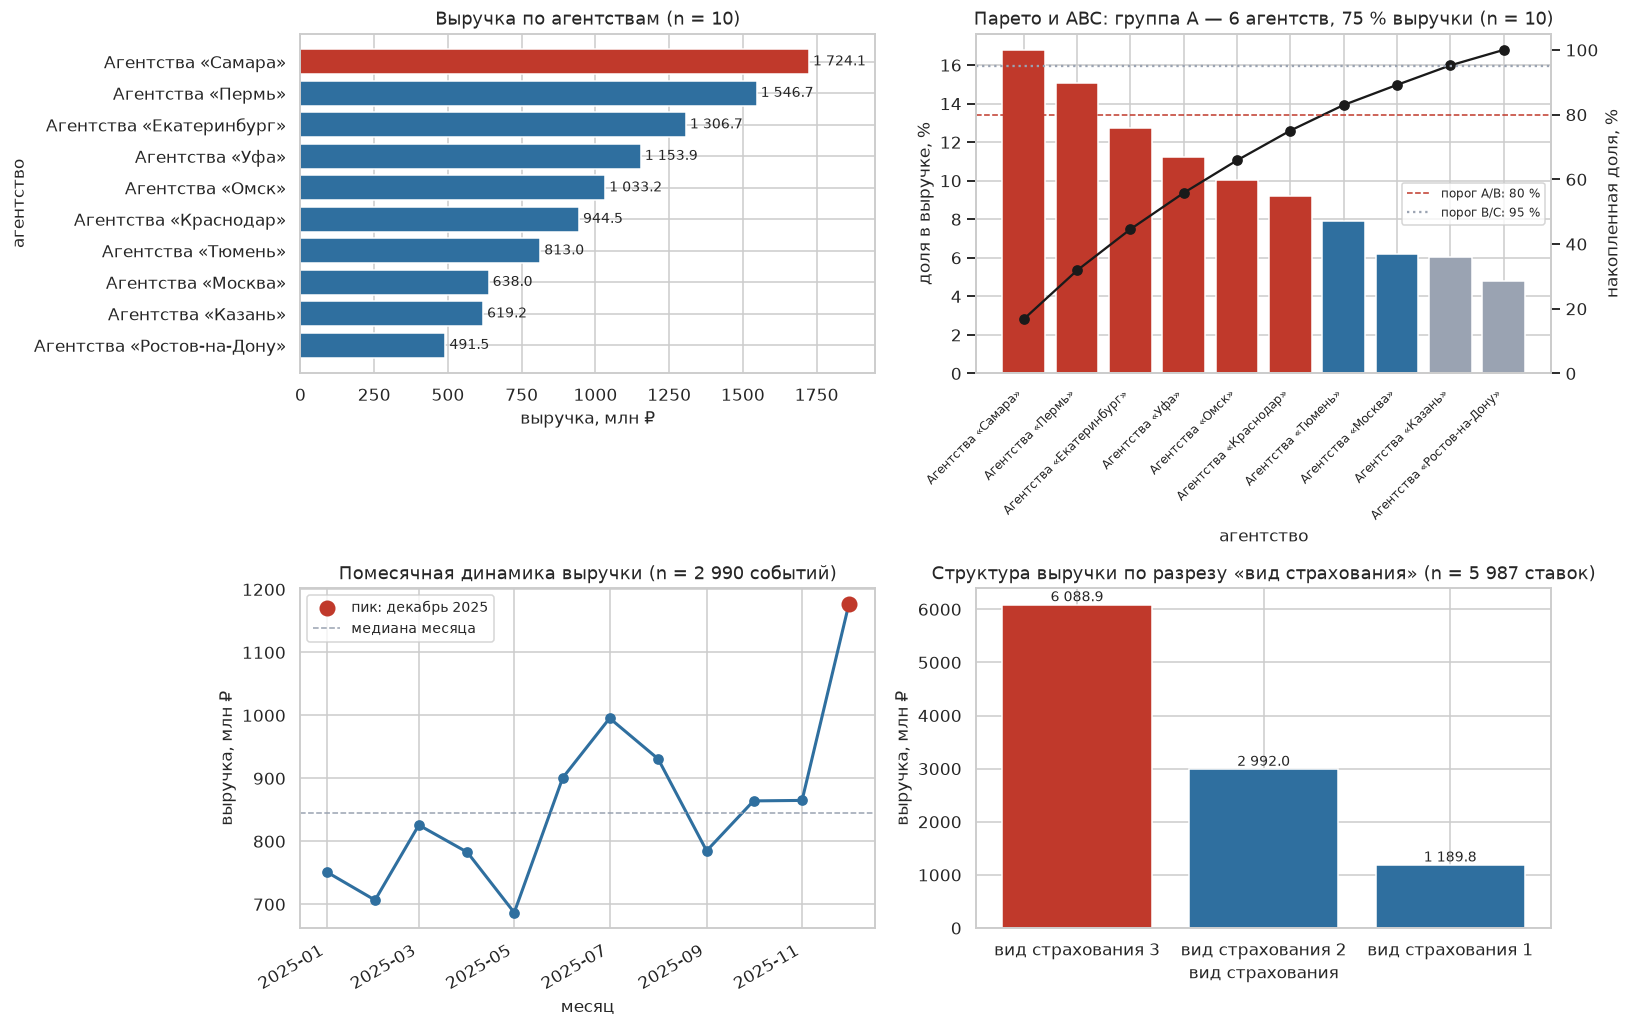

,entity_name,revenue,доля,накопл. доля,группа ABC
0,Агентства «Самара»,"1,724,060,643.69",0.17,0.17,A
1,Агентства «Пермь»,"1,546,691,290.69",0.15,0.32,A
2,Агентства «Екатеринбург»,"1,306,734,255.46",0.13,0.45,A
3,Агентства «Уфа»,"1,153,898,166.32",0.11,0.56,A
4,Агентства «Омск»,"1,033,226,726.08",0.10,0.66,A
5,Агентства «Краснодар»,"944,452,980.85",0.09,0.75,A
6,Агентства «Тюмень»,"812,950,419.35",0.08,0.83,B
7,Агентства «Москва»,"637,970,306.24",0.06,0.89,B
8,Агентства «Казань»,"619,211,208.47",0.06,0.95,C
9,Агентства «Ростов-на-Дону»,"491,497,485.28",0.05,1.00,C


Средняя премия по видам страхования (задача варианта 12)


,тарифных строк,"средняя премия на объект, ₽","выручка, млн ₽","доля в выручке, %"
вид страхования,,,,
вид страхования 1,1989,"5,777.00","1,189.80",11.60
вид страхования 2,1994,"14,907.00","2,992.00",29.10
вид страхования 3,2004,"29,956.00","6,088.90",59.30



================== ВЫВОДЫ ДЛЯ ЛПР ==================
Область            : Страхование (вариант 12)
Данные             : 2 990 событий, 5 987 тарифных строк,
                     10 агентств; в карантине 13 строк (0.1%)
Итоговая выручка   : 10 270 693 482 ₽

1. Концентрация. На три агентства приходится 45% выручки, лидер —
   Агентства «Самара» (16.8%). В группу A (накопленная доля до 80 %)
   входят 6 агентств с 75% выручки: пересмотр условий и комиссий
   разумно начинать с них.
2. Сезонность. Разрыв между лучшим (декабрь 2025) и худшим
   (май 2025) месяцем — в 1.71 раза. Среднегодовое
   планирование такой профиль не покроет: в пик не хватит мощностей, в спад — загрузки.
3. Средняя премия на один объект по видам страхования (задача варианта):
   5 777 ₽ по «вид страхования 1», 14 907 ₽
   по «вид страхования 2» и 29 956 ₽ по «вид страхования 3».
   Самый дорогой вид даёт 59% выручки при трети тарифных строк.
   Вклад агентств — от 4.8% у
   Агентства «Ростов-на-Дону» до 16.8% у лид

In [7]:
#@title Шаг 6. Аналитика и визуализация (задание) { display-mode: "form" }
ACCENT, BASE, GREY = "#c0392b", "#2f6f9f", "#9aa3b2"
RU_MONTHS = ["январь", "февраль", "март", "апрель", "май", "июнь",
             "июль", "август", "сентябрь", "октябрь", "ноябрь", "декабрь"]
# Arial не знает знака рубля — ставлю DejaVu первым, иначе на осях будут пустые клетки
plt.rcParams["font.sans-serif"] = ["DejaVu Sans"] + [
    f for f in plt.rcParams["font.sans-serif"] if f != "DejaVu Sans"]

total_revenue = float(revenue_sql["revenue"].sum())
n_entities = len(revenue_sql)

# ------------------------------------------------------------------ TODO 6.1
top = revenue_sql.sort_values("revenue", ascending=True).reset_index(drop=True)

pareto = revenue_sql.sort_values("revenue", ascending=False).reset_index(drop=True).copy()
pareto["доля"] = pareto["revenue"] / total_revenue
pareto["накопл. доля"] = pareto["доля"].cumsum()
pareto["группа ABC"] = np.where(pareto["накопл. доля"] <= 0.8, "A",
                        np.where(pareto["накопл. доля"] <= 0.95, "B", "C"))
n_group_a = int((pareto["группа ABC"] == "A").sum())
share_a = float(pareto.loc[pareto["группа ABC"] == "A", "доля"].sum())

monthly = (consolidated
           .assign(месяц=consolidated["event_date"].dt.to_period("M").dt.to_timestamp())
           .groupby("месяц", as_index=False)
           .agg(revenue=("event_revenue", "sum"), events=("event_id", "count")))

# Разрез по видам страхования: выручку события делю между его тарифными строками
# (volume × price / n_rows), иначе fan-out снова удвоит сумму разреза
by_class = (prices_valid
            .merge(events_valid[["event_id", "volume_units"]], on="event_id")
            .assign(n_rows=lambda d: d.groupby("event_id")["price_id"].transform("count"))
            .assign(revenue=lambda d: d["volume_units"] * d["unit_price"] / d["n_rows"])
            .groupby("price_class", as_index=False)["revenue"].sum()
            .sort_values("revenue", ascending=False).reset_index(drop=True))
class_gap = abs(float(by_class["revenue"].sum()) - total_revenue)
print(f"Контроль сходимости: разрез «{CFG['cls']}» сходится с итоговой выручкой, "
      f"отклонение {class_gap:.2f} ₽ — сумма любого разреза обязана давать итог")

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

# 1) выручка по агентствам, лидер — акцентом
ax = axes[0, 0]
colors = [ACCENT if i == len(top) - 1 else BASE for i in range(len(top))]
ax.barh(top["entity_name"], top["revenue"] / 1e6, color=colors)
for y, v in enumerate(top["revenue"] / 1e6):
    ax.text(v, y, f" {v:,.1f}".replace(",", " "), va="center", fontsize=9)
ax.set_xlim(0, float(top["revenue"].max()) / 1e6 * 1.13)
ax.set_title(f"Выручка по агентствам (n = {n_entities})")
ax.set_xlabel("выручка, млн ₽"); ax.set_ylabel("агентство")

# 2) Парето с накопленной долей и группами ABC
ax = axes[0, 1]
x = np.arange(len(pareto))
ax.bar(x, pareto["доля"] * 100,
       color=[{"A": ACCENT, "B": BASE, "C": GREY}[g] for g in pareto["группа ABC"]])
ax.set_xticks(x, pareto["entity_name"], rotation=45, ha="right", fontsize=8)
ax.set_xlabel("агентство"); ax.set_ylabel("доля в выручке, %")
ax2 = ax.twinx()
ax2.plot(x, pareto["накопл. доля"] * 100, color="#1a1a1a", marker="o", lw=1.5)
ax2.axhline(80, color=ACCENT, ls="--", lw=1, label="порог A/B: 80 %")
ax2.axhline(95, color=GREY, ls=":", lw=1.5, label="порог B/C: 95 %")
ax2.set_ylim(0, 105); ax2.set_ylabel("накопленная доля, %"); ax2.grid(False)
ax2.legend(loc="center right", fontsize=8)
ax.set_title(f"Парето и ABC: группа A — {n_group_a} агентств, {share_a * 100:.0f} % выручки "
             f"(n = {n_entities})")

# 3) помесячная динамика с пиком и медианой
ax = axes[1, 0]
ax.plot(monthly["месяц"], monthly["revenue"] / 1e6, marker="o", color=BASE, lw=2)
peak = monthly.loc[monthly["revenue"].idxmax()]
def ru_month(ts):
    return f"{RU_MONTHS[ts.month - 1]} {ts.year}"
ax.scatter([peak["месяц"]], [peak["revenue"] / 1e6], color=ACCENT, s=90, zorder=3,
           label=f"пик: {ru_month(peak['месяц'])}")
ax.axhline(monthly["revenue"].median() / 1e6, color=GREY, ls="--", lw=1,
           label="медиана месяца")
ax.set_title(f"Помесячная динамика выручки (n = {nf(len(consolidated))} событий)")
ax.set_xlabel("месяц"); ax.set_ylabel("выручка, млн ₽"); ax.legend(fontsize=9)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

# 4) структура выручки по видам страхования
ax = axes[1, 1]
ax.bar(by_class["price_class"], by_class["revenue"] / 1e6,
       color=[ACCENT if i == 0 else BASE for i in range(len(by_class))])
for i, v in enumerate(by_class["revenue"] / 1e6):
    ax.text(i, v, f"{v:,.1f}".replace(",", " "), ha="center", va="bottom", fontsize=9)
ax.set_title(f"Структура выручки по разрезу «{CFG['cls']}» (n = {nf(len(prices_valid))} ставок)")
ax.set_xlabel("вид страхования"); ax.set_ylabel("выручка, млн ₽")

plt.tight_layout(); plt.show()
PLOTS_DONE = True

display(pareto[["entity_name", "revenue", "доля", "накопл. доля", "группа ABC"]])

# ------------------------------------------------------------------ TODO 6.2
leader = pareto.iloc[0]
share_top3 = float(pareto["доля"].head(3).sum())
season_gap = float(monthly["revenue"].max() / monthly["revenue"].min())
low_month = monthly.loc[monthly["revenue"].idxmin()]
quar_rows = len(quarantine_fk) + len(quarantine_price)
quar_share = quar_rows / max(len(raw_events) + len(raw_prices), 1)
avg_by_class = prices_valid.groupby("price_class")["unit_price"].mean().round(0)
class_share = by_class.set_index("price_class")["revenue"] / total_revenue
premium_table = pd.DataFrame({
    "тарифных строк": prices_valid.groupby("price_class")["price_id"].count(),
    "средняя премия на объект, ₽": avg_by_class,
    "выручка, млн ₽": (by_class.set_index("price_class")["revenue"] / 1e6).round(1),
    "доля в выручке, %": (class_share * 100).round(1),
}).rename_axis(CFG["cls"])
print("Средняя премия по видам страхования (задача варианта 12)")
display(premium_table)
naive_loss = float(compare["revenue_naive"].sum() - compare["revenue"].sum())
avg_event_rev = consolidated["event_revenue"].mean()
lost_events = len(quarantine_fk) + int(events["volume_units"].isna().sum())

print(f"""
================== ВЫВОДЫ ДЛЯ ЛПР ==================
Область            : {CFG['domain']} (вариант {VARIANT})
Данные             : {nf(len(events_valid))} событий, {nf(len(prices_valid))} тарифных строк,
                     {len(entities)} агентств; в карантине {quar_rows} строк ({quar_share:.1%})
Итоговая выручка   : {nf(total_revenue)} ₽

1. Концентрация. На три агентства приходится {share_top3:.0%} выручки, лидер —
   {leader['entity_name']} ({leader['доля']:.1%}). В группу A (накопленная доля до 80 %)
   входят {n_group_a} агентств с {share_a:.0%} выручки: пересмотр условий и комиссий
   разумно начинать с них.
2. Сезонность. Разрыв между лучшим ({ru_month(peak['месяц'])}) и худшим
   ({ru_month(low_month['месяц'])}) месяцем — в {season_gap:.2f} раза. Среднегодовое
   планирование такой профиль не покроет: в пик не хватит мощностей, в спад — загрузки.
3. Средняя премия на один объект по видам страхования (задача варианта):
   {nf(avg_by_class.iloc[0])} ₽ по «{avg_by_class.index[0]}», {nf(avg_by_class.iloc[1])} ₽
   по «{avg_by_class.index[1]}» и {nf(avg_by_class.iloc[2])} ₽ по «{avg_by_class.index[2]}».
   Самый дорогой вид даёт {class_share.max():.0%} выручки при трети тарифных строк.
   Вклад агентств — от {pareto['доля'].min():.1%} у
   {pareto.iloc[-1]['entity_name']} до {leader['доля']:.1%} у лидера.
4. Качество данных. Наивный JOIN завышал выручку в {overstate:.2f} раза — это
   {nf(naive_loss)} ₽ лишней суммы. Отчёт на таком запросе привёл бы к завышенной базе
   решений. SQL и pandas сошлись с расхождением {delta:.4f} ₽.

Рекомендации:
• Перевести расчёт выручки на схему «сворачивание ставок до события → соединение с
  объёмом» и закрыть её автосверкой SQL/pandas с допуском 1 ₽. Эффект — исчезает
  систематическое завышение в {overstate:.2f} раза ({nf(naive_loss)} ₽); проверка —
  ежемесячный прогон сверки и разбор любого расхождения больше рубля.
• Вернуть в оборот потери качества: {quar_rows} карантинных ставок и {lost_events} событий
  без объёма. Оценка недобора — около {nf(lost_events * avg_event_rev)} ₽ ({lost_events}
  событий по средней стоимости {nf(avg_event_rev)} ₽). Эффект — уточнение суммы;
  проверка — доля карантинных строк в следующей загрузке ниже текущей ({quar_share:.1%}).
• Планировать ресурсы по помесячному профилю с коэффициентом {season_gap:.2f} между
  пиком и дном, а не по среднегодовому уровню. Эффект — выравнивание загрузки сети;
  проверка — сравнение плана и факта следующего пикового месяца ({ru_month(peak['месяц'])}).

Ограничения данных: один календарный год (2025), сезонный профиль разовый; города в
маршрутах и годы основания агентств на выручку не влияют — связи с ними не оценивались;
классов тарифа три, взвешивание по объёму внутри вида не выполнялось.
====================================================
""")

# ------------------------------------------------------------------ витрина
# Построчные события с выручкой + сводка по агентствам: файл CSV и те же таблицы в базе
mart_events = (consolidated[["event_id", "entity_id", "entity_name", "event_date",
                             "volume_units", "unit_price", "event_revenue"]]
               .rename(columns={"unit_price": "avg_price"})
               .sort_values("event_id").reset_index(drop=True))
mart_events["event_date"] = mart_events["event_date"].dt.strftime("%Y-%m-%d")
mart_events["volume_units"] = mart_events["volume_units"].round(0).astype(int)
mart_events["avg_price"] = mart_events["avg_price"].round(2)
mart_events["event_revenue"] = mart_events["event_revenue"].round(2)

mart_agents = (pareto[["entity_id", "entity_name", "revenue", "доля", "группа ABC"]]
               .rename(columns={"доля": "share"})
               .assign(share=lambda d: (d["share"] * 100).round(2))
               .reset_index(drop=True))

mart_events.to_sql("dm_revenue_events", conn, if_exists="replace", index=False)
mart_agents.to_sql("dm_revenue_agents", conn, if_exists="replace", index=False)
conn.commit()

csv_path = WORK / "витрина.csv"
(mart_events.merge(mart_agents[["entity_id", "группа ABC"]], on="entity_id", how="left")
 .rename(columns={
    "event_id": "событие", "entity_id": "код агентства", "entity_name": "агентство",
    "event_date": "дата", "volume_units": "объём, объектов",
    "avg_price": "средняя ставка, ₽", "event_revenue": "выручка, ₽",
    "группа ABC": "группа ABC агентства",
 }).to_csv(csv_path, index=False, encoding="utf-8-sig"))

print(f"Витрина: {nf(len(mart_events))} событий в CSV ({csv_path.name}) и в таблице "
      f"dm_revenue_events базы {DB_PATH.name}; сводка по агентствам — в dm_revenue_agents")


**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

## Шаг 7. BigQuery: пошаговое подключение из Colab

Показать, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [8]:
#@title Шаг 7. Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "my-gcp-project"   #@param {type:"string"}
BQ_DATASET = "pw2_consolidation"   #@param {type:"string"}
BQ_LOCATION = "US"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: основная часть работы выполняется на SQLite.


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 1,0 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 2,0 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 2,0 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 2,5 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 1,5 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 1,0 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8–9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7–8 | **C** — расчёт верен, но качество данных проработано формально |
| 6–7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [9]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 баллов)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

In [10]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# A. Инкрементальная загрузка.
#    Сгенерируйте «следующий день» данных и реализуйте догрузку через UPSERT
#    (INSERT ... ON CONFLICT DO UPDATE) вместо полной перезаписи. Покажите, что повторный
#    запуск не создаёт дубликатов (идемпотентность).
#
# B. Медленно меняющиеся измерения (SCD Type 2).
#    Субъект сменил название. Реализуйте историчность справочника (valid_from, valid_to, is_current)
#    и покажите, что выручка прошлых периодов осталась привязана к прежнему названию.
#
# C. Автотесты качества данных.
#    Оформите проверки шага 3 как набор тестов (assert или pytest), которые запускаются
#    при каждой загрузке и останавливают конвейер при падении критичных правил.
#
# D. Взвешенная цена вместо средней.
#    Сейчас цены сворачиваются простым средним. Если известно число проданных единиц по классам,
#    корректнее взвешенное среднее. Реализуйте и покажите, как меняется выручка и почему.
#
# E. Сравнение движков.
#    Замерьте время корректного расчёта на pandas, SQLite и (если включали) BigQuery
#    при объёме в 10 раз больше. Постройте график и объясните, где проходит граница применимости.